In [1]:
import json
import joblib
import warnings
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

 
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
 
warnings.filterwarnings('ignore')
 

In [2]:
# 2. Read Data
df = pd.read_csv("../data/SAML-D.csv", header = 0, sep = ',')

In [7]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [5]:
count_laundering = (df["Is_laundering"] == 1).sum()

print("Number of rows where Is_laundering = 1:", count_laundering)

Number of rows where Is_laundering = 1: 9873


In [16]:
import pandas as pd

# Separate laundering and normal transactions
laundering_df = df[df["Is_laundering"] == 1]
normal_df = df[df["Is_laundering"] == 0]

# Target dataset size
target_rows = 500_000

# Calculate the number of normal transactions to sample
normal_sample_size = target_rows - len(laundering_df)

# Keep all laundering rows and sample normal rows
normal_sample_df = normal_df.sample(
    n=normal_sample_size,
    random_state=42
)

# Combine both datasets
df_sample = pd.concat(
    [laundering_df, normal_sample_df],
    ignore_index=True
)

# Shuffle the dataset
df_sample = df_sample.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Verify the results
print("Original dataset shape:", df.shape)
print("Sample dataset shape:", df_sample.shape)
print("\nTarget distribution:")
print(df_sample["Is_laundering"].value_counts())

print("\nAll laundering rows retained:",
      (df_sample["Is_laundering"] == 1).sum()
      == (df["Is_laundering"] == 1).sum())

Original dataset shape: (9504852, 12)
Sample dataset shape: (500000, 12)

Target distribution:
Is_laundering
0    490127
1      9873
Name: count, dtype: int64

All laundering rows retained: True


In [17]:
# Convert Date to integer in YYYYMMDD format
df_sample["Date"] = pd.to_datetime(
    df_sample["Date"], errors="coerce"
).dt.strftime("%Y%m%d").pipe(pd.to_numeric, errors="coerce").astype("Int64")

# Convert Time (HH:MM:SS) to integer in HHMMSS format
df_sample["Time"] = pd.to_datetime(
    df_sample["Time"], format="%H:%M:%S", errors="coerce"
).dt.strftime("%H%M%S").pipe(pd.to_numeric, errors="coerce").astype("Int64")

# Verify
print(df_sample[["Date", "Time"]].head())
print(df_sample[["Date", "Time"]].dtypes)

       Date    Time
0  20230226  154739
1  20230507   82252
2  20230717  235157
3  20230429  130439
4  20230115   62903
Date    Int64
Time    Int64
dtype: object


In [18]:
df_sample.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,154739,20230226,6964651170,2762814098,202.10,UK pounds,UK pounds,UK,UK,Debit card,0,Normal_Small_Fan_Out
1,82252,20230507,6355446865,4180638099,224.02,Turkish lira,UK pounds,Turkey,UK,Cross-border,0,Normal_Small_Fan_Out
2,235157,20230717,9398298924,8541987572,12826.30,UK pounds,UK pounds,UK,UK,Credit card,0,Normal_Small_Fan_Out
3,130439,20230429,8083055622,4191816372,5301.54,UK pounds,UK pounds,UK,UK,Debit card,0,Normal_Fan_In
4,62903,20230115,5950027791,6849686539,7310.49,UK pounds,UK pounds,UK,UK,Credit card,0,Normal_Fan_In


In [19]:
df_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Time                    500000 non-null  Int64  
 1   Date                    500000 non-null  Int64  
 2   Sender_account          500000 non-null  int64  
 3   Receiver_account        500000 non-null  int64  
 4   Amount                  500000 non-null  float64
 5   Payment_currency        500000 non-null  str    
 6   Received_currency       500000 non-null  str    
 7   Sender_bank_location    500000 non-null  str    
 8   Receiver_bank_location  500000 non-null  str    
 9   Payment_type            500000 non-null  str    
 10  Is_laundering           500000 non-null  int64  
 11  Laundering_type         500000 non-null  str    
dtypes: Int64(2), float64(1), int64(3), str(6)
memory usage: 69.5 MB


In [20]:
# Split The Data Into Train And Test Sets
X = df_sample.drop('Is_laundering', axis = 1)
Y = df_sample['Is_laundering']

In [35]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 2, stratify = Y)
 

In [21]:
numerical_features = X.select_dtypes(
    include = ['int64', "float64"]
).columns.tolist()
 
categorical_features = X.select_dtypes(
    include = ["object"]
).columns.tolist()
 

In [22]:
print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount']
Categorical Features: ['Payment_currency', 'Received_currency', 'Sender_bank_location', 'Receiver_bank_location', 'Payment_type', 'Laundering_type']


<Axes: xlabel='Is_laundering', ylabel='count'>

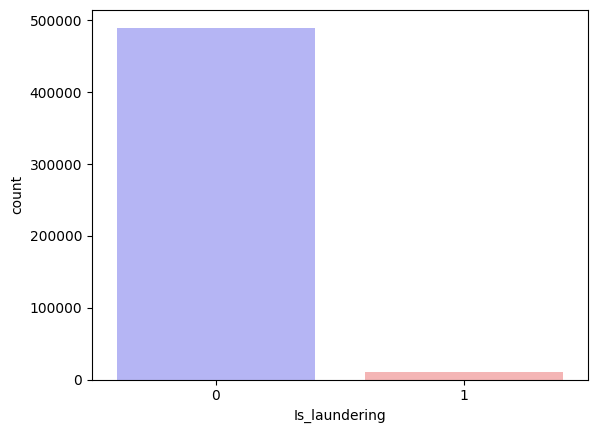

In [23]:
sns.countplot(x = 'Is_laundering', data = df_sample, palette = 'bwr')

Is_laundering         0     1
Payment_type                 
ACH              103946  1159
Cash Deposit      11604  1405
Cash Withdrawal   15458  1334
Cheque           103042  1087
Credit card      103688  1136
Cross-border      48664  2628
Debit card       103725  1124


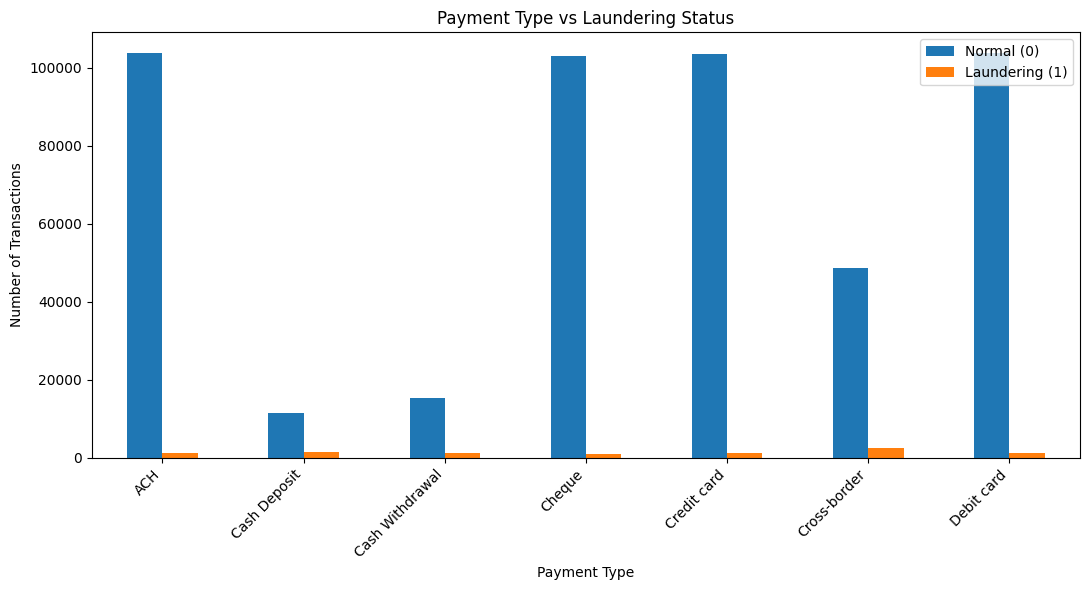

In [26]:
payment_counts = pd.crosstab(
    df_sample["Payment_type"],
    df_sample["Is_laundering"]
)

print(payment_counts)

payment_counts.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Payment Type vs Laundering Status")
plt.xlabel("Payment Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.legend(["Normal (0)", "Laundering (1)"])
plt.tight_layout()
plt.show()

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [31]:
numerical_pipeline = Pipeline(
    steps = [
        ("inputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
 
categorical_pipeline = Pipeline(
    steps = [
        ("inputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
 


In [32]:
preprocessor = ColumnTransformer(
    transformers= [
        ("num" , numerical_pipeline, numerical_features),
         ("cat" , categorical_pipeline, categorical_features)]
)

In [43]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE()),
        ("classifier", LogisticRegression(
            solver="lbfgs",
            max_iter=10000,
            C=1,
            penalty="l2"
        ))
    ]
)

In [44]:
model_pipeline.fit(X_train, Y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](11,)","['Time','Date','Sender_account',...,'Receiver_bank_location', 'Payment_type','Laundering_type']"
n_features_in_,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [45]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [46]:
y_pred_Logistic = model_pipeline.predict(X_test)

In [47]:
# This is matrix between Actual Value and Predicted Value
confusion_matrix(Y_test, y_pred_Logistic)

array([[98025,     0],
       [    0,  1975]])

In [48]:
print(classification_report(Y_test, y_pred_Logistic))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     98025
           1       1.00      1.00      1.00      1975

    accuracy                           1.00    100000
   macro avg       1.00      1.00      1.00    100000
weighted avg       1.00      1.00      1.00    100000



In [51]:
model_pipeline.score(X_train,Y_train)

1.0

In [76]:
joblib.dump(model_pipeline, "../model/Logistic_Regression.pkl")

['../model/Logistic_Regression.pkl']

In [52]:
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

dt_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE()),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=None,
            ccp_alpha=0.0,
            random_state=42
        ))
    ]
)



In [58]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [5, 10, 20, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__ccp_alpha": [0.0, 0.001, 0.01]
}

In [59]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search_dt = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

In [61]:
grid_search_dt.fit(X_test, Y_test)

Fitting 3 folds for each of 96 candidates, totalling 288 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__ccp_alpha': [0.0, 0.001, ...], 'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_leaf': [1, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``

In [62]:
print("Best Parameters:")
print(grid_search_dt.best_params_)

print("\nBest Cross-Validation Average Precision:")
print(grid_search_dt.best_score_)

Best Parameters:
{'classifier__ccp_alpha': 0.0, 'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best Cross-Validation Average Precision:
1.0


In [64]:
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

dt_pipeline1 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE()),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=20,
            ccp_alpha=0.0,
            random_state=42
        ))
    ]
)


In [65]:
dt_pipeline1.fit(X_train, Y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](11,)","['Time','Date','Sender_account',...,'Receiver_bank_location', 'Payment_type','Laundering_type']"
n_features_in_,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [66]:
dt_pipeline1.score(X_train, Y_train)

1.0

In [71]:
y_pred_RF = dt_pipeline1.predict(X_test)

In [72]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(Y_test, y_pred_RF))

print("\nClassification Report:")
print(classification_report(Y_test, y_pred_RF))

Confusion Matrix:
[[98025     0]
 [    0  1975]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     98025
           1       1.00      1.00      1.00      1975

    accuracy                           1.00    100000
   macro avg       1.00      1.00      1.00    100000
weighted avg       1.00      1.00      1.00    100000



In [77]:
joblib.dump(dt_pipeline1, "../model/Decision_Tree.pkl")

['../model/Decision_Tree.pkl']

In [67]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", RandomForestClassifier(
            bootstrap=True,
            n_estimators=50,
            max_depth=15,
            random_state=2,
            max_features=10
        ))
    ]
)


In [68]:
rf_pipeline.fit(X_train, Y_train)



,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](11,)","['Time','Date','Sender_account',...,'Receiver_bank_location', 'Payment_type','Laundering_type']"
n_features_in_,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [69]:
y_pred_RF = rf_pipeline.predict(X_test)

In [70]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(Y_test, y_pred_RF))

print("\nClassification Report:")
print(classification_report(Y_test, y_pred_RF))

Confusion Matrix:
[[97793   232]
 [    0  1975]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     98025
           1       0.89      1.00      0.94      1975

    accuracy                           1.00    100000
   macro avg       0.95      1.00      0.97    100000
weighted avg       1.00      1.00      1.00    100000



In [78]:
joblib.dump(rf_pipeline, "../model/Random_Forest.pkl")

['../model/Random_Forest.pkl']